# Lesioning analysis of the Shannon observables

This notebook reproduces the lesioning results on the MNIST classifier of the
Shannon-observables paper. It **reuses the checkpoints of existing
experiments** and does not train anything, so it runs in a few minutes.

A neuron is lesioned by clamping its activation to zero, without rescaling the
surviving activations, at epoch $10^4$; the lesion damage is the resulting drop
in test accuracy. All evaluations use the stochastic 8-level quantization of
training and of the information-theoretic measurements.

Paper outputs, saved to `../experiments/exp_mnist_8levels_onehot/plots/` under
the manuscript's file names:

- **Figure 3d**, `feedforward_mnist_lesioning.pdf` -- lesion damage against the
  per-neuron vulnerability $v_i = I(X_i;Y\mid \bm X_{-i})/I(\bm X;Y)$
  (section 3);
- **Figure 7** (appendix), `importance_comparison.pdf`, and the Spearman
  correlations of **Table III** -- comparison with conventional importance
  measures (section 4);
- **Figure 3c**, `feedforward_mnist_lesionbars.pdf` -- lesion damage of the
  standard networks and of the networks trained with one-neuron dropout
  (section 5), with the mean damages quoted in the Results.

Sections 1 and 2 (lesion damage per layer for several lesion surrogates, and
the observables of the lesioned code) are supplementary.

> **Layer labelling.** `nninfo` labels *every* entry of `layer_infos`,
> including the input layer, so the three five-neuron layers are `L4`, `L5`,
> `L6`. The papers label only the weighted layers and call the same layers
> L3-L5; the figures use the paper's labels.

Prerequisites: `exp_mnist_8levels_onehot` with checkpoints and the
`summary_measurement_L{4,5,6}_stochastic` measurements (notebook 1 or
`scripts/compute_shannon_observables.py`); for section 5, the single-layer
dropout experiments of notebook 4.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

import nninfo
from nninfo.model.quantization import quantizer_list_factory
from nninfo.analysis.lesioning import lesion_scan
from nninfo.analysis.empirical import code_observables
from nninfo.analysis.importance import collect_importances
from nninfo.postprocessing.shannon_observables import (
    add_shannon_observables, per_source_vulnerability)

cm = 1 / 2.54

# Match the font of the assembled paper figure (falls back to DejaVu Sans
# if Arial is unavailable).
plt.rcParams.update({'font.family': 'sans-serif',
                     'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                     'mathtext.fontset': 'dejavusans'})

N_WORKERS=16


nninfo startup took 0.21579141612164676s


/Users/david/miniforge3/envs/nninfo/lib/python3.10/site-packages/sxpid/SxPID.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename  # type: ignore


In [3]:
experiment_id = "mnist_8levels_onehot"
CHAPTER = 38          # epoch 10_000 on the log-spaced schedule
LAYER_INDICES = [3, 4, 5]                     # layer_infos indices
LAYER_LABELS = [f"L{i+1}" for i in LAYER_INDICES]   # -> L4, L5, L6
COLORS = {"L4": "tab:blue", "L5": "tab:orange", "L6": "tab:green"}
# the paper's labels for the same layers
PAPER_LABELS = {"L4": "$L_3$", "L5": "$L_4$", "L6": "$L_5$"}

# stochastic quantization, matching training and the deg_red / deg_vuln
# measurements. Reproducible despite the stochastic rounding: every
# load_checkpoint() restores the saved torch RNG state before evaluation.
QUANTIZER_PARAMS = ([None]
                    + 5 * [{"levels": 8, "rounding_point": "stochastic"}]
                    + [None])

experiment = nninfo.Experiment.load(experiment_id)
run_ids = experiment.checkpoint_manager.get_run_ids()[:10]
quantizers = quantizer_list_factory(QUANTIZER_PARAMS,
                                    experiment.network.get_limits_list())
assert experiment.schedule.get_epoch_for_chapter(CHAPTER) == 10_000
print("runs:", run_ids, "| epoch:",
      experiment.schedule.get_epoch_for_chapter(CHAPTER))

nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


Loading experiment mnist_8levels_onehot
config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0}
toch seed hash: -971162748514821796
runs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | epoch: 10000


In [4]:
# Test data. The labels are taken from the pipeline; nninfo's
# qmnist_class_labels() guards against a torchvision bug that returns zeros
# for the QMNIST half of the test set on some platforms.
dataset = experiment.task["full_set/test"]
x_test, y_test = next(iter(DataLoader(dataset, batch_size=len(dataset))))
y_test = y_test.long()
assert len(torch.unique(y_test)) == 10, "test labels look invalid"
print(x_test.shape, y_test.shape)

torch.Size([60000, 784]) torch.Size([60000])


## 1. Lesion damage per layer

One neuron at a time is clamped to zero (the lesion is injected by wrapping
that layer's quantizer, so it lands exactly on the activations the
information-theoretic analysis sees).

In [5]:
lesion = lesion_scan(experiment, x_test, y_test, quantizers,
                     layer_indices=LAYER_INDICES, run_ids=run_ids,
                     chapter_id=CHAPTER, mode="zero")
per_run = lesion.groupby(["layer", "run_id"])["accuracy_drop"].mean().reset_index()
print(per_run.groupby("layer")["accuracy_drop"].agg(["mean", "sem"]))

toch seed hash: 279664877507515119


toch seed hash: -1779696006536128463


toch seed hash: -3317180370472369904


toch seed hash: 2417425231416141170


toch seed hash: 7049043367516427699


toch seed hash: -8427915489839563820


toch seed hash: 2458353019100281290


toch seed hash: 1698931734143518818


toch seed hash: -13638916534813318


toch seed hash: 847461216368227692


           mean       sem
layer                    
L4     0.168975  0.017758
L5     0.100094  0.007415
L6     0.027827  0.006936


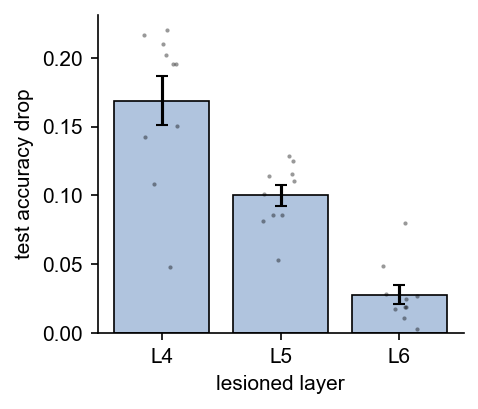

In [6]:
fig, ax = plt.subplots(figsize=(8*cm, 7*cm), dpi=150)
xs = np.arange(len(LAYER_LABELS))
means = [per_run[per_run.layer == l]["accuracy_drop"].mean() for l in LAYER_LABELS]
sems  = [per_run[per_run.layer == l]["accuracy_drop"].sem()  for l in LAYER_LABELS]
ax.bar(xs, means, yerr=sems, capsize=3, color="lightsteelblue",
       edgecolor="k", linewidth=.8, zorder=2)
rng = np.random.default_rng(0)
for xi, l in zip(xs, LAYER_LABELS):
    v = per_run[per_run.layer == l]["accuracy_drop"]
    ax.scatter(xi + rng.uniform(-.15, .15, len(v)), v, s=4, c="k",
               alpha=.4, zorder=3, lw=0)
ax.set_xticks(xs); ax.set_xticklabels(LAYER_LABELS)
ax.set_xlabel("lesioned layer"); ax.set_ylabel("test accuracy drop")
ax.spines[["top", "right"]].set_visible(False)

### Other lesion surrogates

`mode='mean'` clamps the neuron to its dataset mean and `mode='shuffle'`
permutes it across samples (preserving its marginal). All three satisfy the
Markov condition behind the ablation bounds, but they differ in how much
*interference* they inject into the frozen downstream decoder.

In [7]:
alt = {m: lesion_scan(experiment, x_test, y_test, quantizers,
                      layer_indices=LAYER_INDICES, run_ids=run_ids[:5],
                      chapter_id=CHAPTER, mode=m)
       for m in ("mean", "shuffle")}
for m, df in alt.items():
    print(m, df.groupby("layer")["accuracy_drop"].mean().round(4).to_dict())

toch seed hash: 7502400803600431321


toch seed hash: -852732895293429751


toch seed hash: -2789074057625324136


toch seed hash: 5480083647724457559


toch seed hash: 7247342554277609325


toch seed hash: -3592065540901772118


toch seed hash: -5836390894719916726


toch seed hash: -8353681126688924856


toch seed hash: 4166740530975629641


toch seed hash: 3336057605736667705


mean {'L4': 0.1641, 'L5': 0.1076, 'L6': 0.0369}
shuffle {'L4': 0.322, 'L5': 0.3028, 'L6': 0.2903}


## 2. Redundancy and vulnerability of the lesioned code

Removing neurons does not just delete information -- it *restructures* what
remains. Here every subset of L4 is removed and the observables of the
surviving sub-code are recomputed directly from the activations.

In [8]:
from itertools import combinations

STOCH = [None] + 5 * [{"levels": 8, "rounding_point": "stochastic"}] + [None]
stoch_q = quantizer_list_factory(STOCH, experiment.network.get_limits_list())
train = experiment.task["full_set/train"]
x_tr, y_tr = next(iter(DataLoader(train, batch_size=len(train))))
y_tr = y_tr.numpy()

rows = []
for run_id in run_ids[:3]:            # 3 runs keeps this cell quick
    experiment.load_checkpoint(run_id, CHAPTER)
    with torch.no_grad():
        _, acts = experiment.network.forward(x_tr, quantizers=stoch_q,
                                             return_activations=True)
    A = acts["L4"]
    for k in range(4):                # 0..3 lesioned neurons
        for lesioned in combinations(range(5), k):
            survivors = [i for i in range(5) if i not in lesioned]
            inv = code_observables(A, y_tr, neurons=survivors)
            rows.append({"run_id": run_id, "k": k, **inv})
seq = pd.DataFrame(rows)
print(seq.groupby("k")[["total_MI", "deg_red", "deg_vuln"]].mean().round(3))

toch seed hash: 7712028883756616830


toch seed hash: -5918242263289292445


toch seed hash: -9061591642606837323


   total_MI  deg_red  deg_vuln
k                             
0     3.315    1.684     0.186
1     3.192    1.401     0.457
2     2.826    1.188     0.763
3     2.105    1.063     0.937


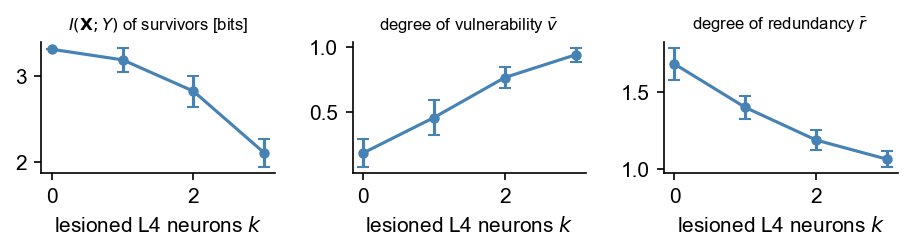

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16*cm, 4.5*cm), dpi=150)
for ax, col, lab in zip(axes, ["total_MI", "deg_vuln", "deg_red"],
                        ["$I(\\mathbf{X};Y)$ of survivors [bits]",
                         "degree of vulnerability $\\bar{v}$",
                         "degree of redundancy $\\bar{r}$"]):
    g = seq.groupby("k")[col]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                marker="o", ms=4, capsize=3, c="steelblue")
    ax.set_xlabel("lesioned L4 neurons $k$"); ax.set_title(lab, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## 3. Lesion damage vs. the degree of vulnerability

The per-neuron contribution $v_i$ to $\bar v$ is read off the stored
`deg_red` measurement. It is the quantity the ablation bounds of the appendix
are about: it lower-bounds the loss any decoder must suffer.

In [10]:
vuln = []
for layer_idx, label in zip(LAYER_INDICES, LAYER_LABELS):
    res = pd.read_hdf(experiment.experiment_dir
                      / f"summary_measurement_{label}_stochastic" / "results.h5",
                      "results")
    per = per_source_vulnerability(res[res.epoch_id == 10_000])
    per["layer"] = label
    vuln.append(per)
vuln = pd.concat(vuln, ignore_index=True)

merged = vuln.merge(lesion[["run_id", "layer", "neuron", "accuracy_drop"]],
                    on=["run_id", "layer", "neuron"])
# Spearman rank correlations, as reported in the paper
rho, p = spearmanr(merged.v_i, merged.accuracy_drop)
print(f"pooled Spearman rho = {rho:+.2f} (p={p:.1e}), n={len(merged)}")
for l in LAYER_LABELS:
    s = merged[merged.layer == l]
    rho, p = spearmanr(s.v_i, s.accuracy_drop)
    print(f"  {l} (paper {PAPER_LABELS[l]}): rho = {rho:+.2f} (p={p:.1e})")

pooled Spearman rho = +0.72 (p=2.4e-25), n=150
  L4 (paper $L_3$): rho = +0.47 (p=5.7e-04)
  L5 (paper $L_4$): rho = +0.61 (p=2.3e-06)
  L6 (paper $L_5$): rho = +0.83 (p=1.1e-13)


## 4. Comparison with conventional importance measures

Weight norms and activation statistics are the usual proxies for "how
important is this unit". Note that raw incoming/outgoing L2 norms are **not
comparable between layers**, because the weight vectors have as many entries
as the adjacent layers are wide -- only the within-layer correlations (and the
`*_rel` variants) are meaningful across layers.

In [11]:
# The importance measures are computed on **full_set/train**, the same data the
# deg_red measurements (and hence v_i) are estimated on, so the comparison is
# like-for-like. Only the lesion damage is a test-set quantity, as it must be.
# NB: the pooled Taylor correlation is sensitive to this choice (it even flips
# sign on the test set) -- another symptom of the between-layer confound that
# makes pooled magnitude-based statistics unreliable.
y_tr_t = torch.as_tensor(y_tr).long()
imp = collect_importances(experiment, x_tr, y_tr_t, LAYER_INDICES,
                          run_ids, CHAPTER, quantizers)
full = imp.merge(merged[["run_id", "layer", "neuron", "v_i", "accuracy_drop"]],
                 on=["run_id", "layer", "neuron"])

# Table III: Spearman rank correlation between each measure and the lesion
# damage (two-sided p-value in parentheses), within each layer (n=50 neuron
# lesions) and pooled (n=150). Columns use the paper's layer labels. The
# *_rel and act_pct rows are supplementary.
def spearman_cell(x, y):
    rho, p = spearmanr(x, y)
    return f"{rho:+.2f} ({p:.2g})"

table = {}
for c in ["v_i", "in_norm", "out_norm", "act_std", "mean_abs", "taylor",
          "in_norm_rel", "out_norm_rel", "act_pct"]:
    row = {f"L{int(l[1:]) - 1}": spearman_cell(full[full.layer == l][c],
                                               full[full.layer == l].accuracy_drop)
           for l in LAYER_LABELS}
    row["pooled"] = spearman_cell(full[c], full.accuracy_drop)
    table[c] = row
pd.DataFrame(table).T

toch seed hash: -7824598547187855521
toch seed hash: 8398740012408082713
toch seed hash: -732569138991945462
toch seed hash: -5571371931961092462


toch seed hash: 4389061943786999283


toch seed hash: -1152788176590253769
toch seed hash: -8184245854518744226
toch seed hash: -8522138365767819888
toch seed hash: 6384557843276181141


toch seed hash: -2903224912090674608


,L3,L4,L5,pooled
v_i,+0.47 (0.00057),+0.61 (2.3e-06),+0.83 (1.1e-13),+0.72 (2.4e-25)
in_norm,+0.36 (0.011),-0.25 (0.08),+0.27 (0.063),+0.19 (0.017)
out_norm,+0.12 (0.42),+0.57 (1.5e-05),+0.28 (0.049),-0.40 (4.4e-07)
act_std,+0.40 (0.0045),-0.25 (0.084),+0.20 (0.16),+0.13 (0.11)
mean_abs,+0.24 (0.092),-0.20 (0.17),+0.29 (0.038),+0.13 (0.1)
taylor,+0.21 (0.15),+0.20 (0.17),+0.30 (0.032),-0.30 (0.00019)
in_norm_rel,+0.20 (0.17),-0.24 (0.089),+0.18 (0.22),+0.03 (0.7)
out_norm_rel,+0.15 (0.31),+0.64 (6.3e-07),+0.36 (0.0096),+0.29 (0.00036)
act_pct,+0.21 (0.14),-0.12 (0.42),+0.20 (0.17),-0.00 (0.99)


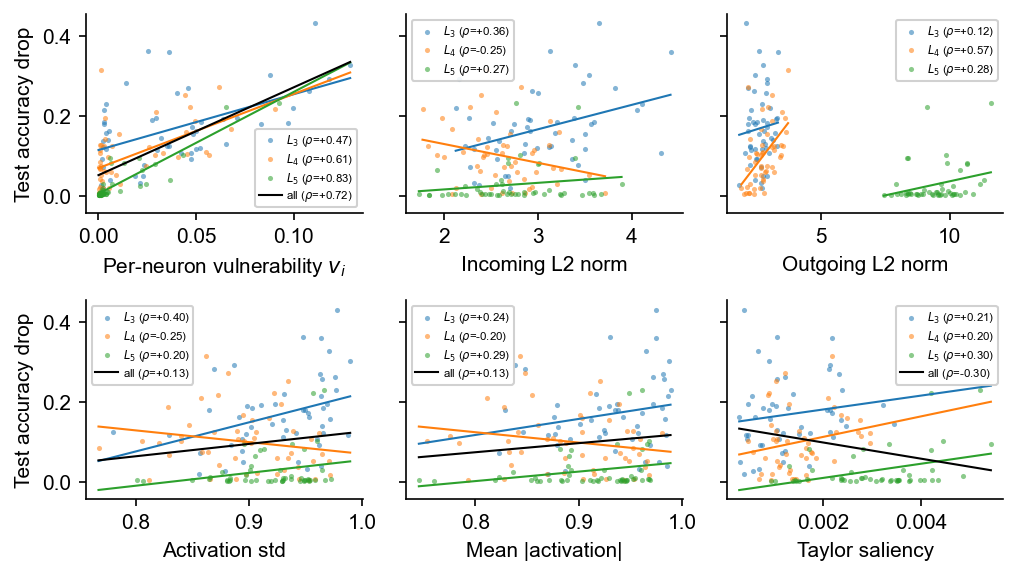

In [12]:
# Figure 7 (appendix): lesion damage against v_i and standard importance
# measures, in the styling of the main-text figure (paper labels L3-L5).
# Pooled (black) fits are drawn only where a measure is comparable across
# layers; the raw weight norms are not (their dimension depends on the
# adjacent layer widths), so those panels show within-layer fits only.
SPECS_PAPER = [("v_i", "Per-neuron vulnerability $v_i$", True),
               ("in_norm", "Incoming L2 norm", False),
               ("out_norm", "Outgoing L2 norm", False),
               ("act_std", "Activation std", True),
               ("mean_abs", "Mean |activation|", True),
               ("taylor", "Taylor saliency", True)]

fig, axes = plt.subplots(2, 3, figsize=(17.5*cm, 10*cm), dpi=150, sharey=True)
for ax, (col, xlabel, pooled) in zip(axes.ravel(), SPECS_PAPER):
    for l, c in COLORS.items():
        s = full[full.layer == l]
        ax.scatter(s[col], s.accuracy_drop, s=6, c=c, alpha=.55, lw=0,
                   label=f"{PAPER_LABELS[l]} ($\\rho$={spearmanr(s[col], s.accuracy_drop)[0]:+.2f})")
        k = np.polyfit(s[col], s.accuracy_drop, 1)
        # fits span the full x-range where layers are comparable (pooled panels)
        xs = (np.linspace(full[col].min(), full[col].max(), 40) if pooled
              else np.linspace(s[col].min(), s[col].max(), 40))
        ax.plot(xs, np.polyval(k, xs), c=c, lw=1.)
    if pooled:
        k = np.polyfit(full[col], full.accuracy_drop, 1)
        xs = np.linspace(full[col].min(), full[col].max(), 40)
        ax.plot(xs, np.polyval(k, xs), "k-", lw=1.,
                label=f"all ($\\rho$={spearmanr(full[col], full.accuracy_drop)[0]:+.2f})")
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=5.5, framealpha=.9, handletextpad=.4, borderpad=.3,
              labelspacing=.25)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Test accuracy drop")
fig.tight_layout()
plt.savefig(f"../experiments/exp_{experiment_id}/plots/importance_comparison.pdf",
            bbox_inches='tight')

**Result.** Only $v_i$ correlates with lesion damage consistently: it is
positive and significant *within every layer* as well as pooled. The weight
norms give sign-inconsistent within-layer correlations, and the activation
statistics carry essentially no signal -- these quantized tanh units are
saturated and active on nearly every sample, so there is little variation in
"how active" a neuron is.

## 5. Lesion damage of dropout-trained networks

The networks trained with one-neuron dropout on a single layer (notebook 4)
have a near-zero degree of vulnerability in that layer. If $\bar v$ carries
the operational meaning established above, lesioning the protected layer
should cause far less damage than lesioning the same layer in the standard
networks. Note the dropout experiments carry the `one_neuron_dropout` layer
in their `layer_infos`, so their quantizer list is taken from their own
training config (it has a `None` entry at the dropout layer's position); the
protected layer's label is unshifted because the dropout layer sits directly
behind it.


In [13]:
DROPOUT_EXPERIMENTS = {"L4": "mnist_8levels_onehot_dropout_L4",
                       "L5": "mnist_8levels_onehot_dropout_L5",
                       "L6": "mnist_8levels_onehot_dropout_L6"}

drop_lesion = []
for label, exp_id in DROPOUT_EXPERIMENTS.items():
    exp_d = nninfo.Experiment.load(exp_id)
    run_ids_d = exp_d.checkpoint_manager.get_run_ids()[:10]
    # the protected layer sits directly before the one_neuron_dropout layer
    drop_idx = next(i for i, li in enumerate(exp_d.network._layer_infos)
                    if li.connection_layer == "one_neuron_dropout")
    layer_idx = drop_idx - 1
    assert f"L{layer_idx + 1}" == label
    q_d = quantizer_list_factory(exp_d.trainer._quantizer_params,
                                 exp_d.network.get_limits_list())
    df = lesion_scan(exp_d, x_test, y_test, q_d, layer_indices=[layer_idx],
                     run_ids=run_ids_d, chapter_id=CHAPTER, mode="zero")
    df["condition"] = "dropout"
    drop_lesion.append(df)
drop_lesion = pd.concat(drop_lesion, ignore_index=True)

base_lesion = lesion[["run_id", "layer", "neuron", "accuracy_drop"]].copy()
base_lesion["condition"] = "full"
both = pd.concat([base_lesion,
                  drop_lesion[["run_id", "layer", "neuron", "accuracy_drop",
                               "condition"]]], ignore_index=True)
print(both.groupby(["layer", "condition"]).accuracy_drop.agg(["mean", "sem"]).round(4))

# Mean lesion damage over neurons and runs in percent, as quoted in the
# Results (2.8-16.9 % for the standard networks, below 0.3 % with dropout)
print((100 * both.groupby(["condition", "layer"]).accuracy_drop.mean()).round(2))

nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


Loading experiment mnist_8levels_onehot_dropout_L4
config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0, 'reg_str': None, 'reg_args': None}
toch seed hash: -414741307270346556
toch seed hash: 718017180853969663


toch seed hash: 7072000873883257126


toch seed hash: 4477695800744717820


toch seed hash: 1843711935442872572


... (27 outputs left out)

toch seed hash: 1547091983306865621


toch seed hash: 4952208276984707976


toch seed hash: -7243685632595712665


                   mean     sem
layer condition                
L4    dropout    0.0025  0.0002
      full       0.1690  0.0131
L5    dropout    0.0011  0.0001
      full       0.1001  0.0107
L6    dropout    0.0006  0.0001
      full       0.0278  0.0071
condition  layer
dropout    L4        0.25
           L5        0.11
           L6        0.06
full       L4       16.90
           L5       10.01
           L6        2.78
Name: accuracy_drop, dtype: float64


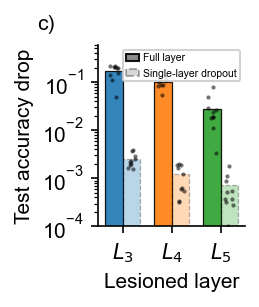

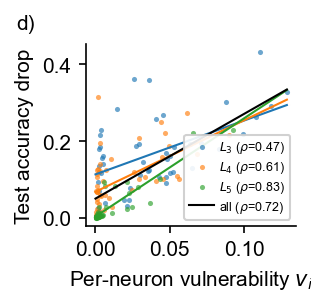

In [14]:
# Figure 3 (c): lesion damage of the standard networks and of the networks
# trained with one-neuron dropout on the lesioned layer (log scale; bars: mean
# over neurons and runs, dots: run means).
# Figure 3 (d): per-neuron vulnerability against lesion damage, with per-layer
# and pooled least-squares fits as visual guides.
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(3.2*cm, 4*cm), dpi=150)
xs = np.arange(3)
W = .36
rng = np.random.default_rng(0)
# dropout bars: lighter fill and dashed border, matching the dashed-line
# convention of the other panels
for off, cond, ls in [(-W/2, "full", "-"), (W/2, "dropout", "--")]:
    for xi, l in zip(xs, ["L4", "L5", "L6"]):
        v = both[(both.layer == l) & (both.condition == cond)]
        per_run = v.groupby("run_id").accuracy_drop.mean()
        ax.bar(xi + off, v.accuracy_drop.mean(), width=W,
               color=COLORS[l], alpha=.9 if cond == "full" else .3,
               edgecolor="k", linewidth=.6, linestyle=ls, zorder=2, bottom=1e-4)
        ax.scatter(xi + off + rng.uniform(-.09, .09, len(per_run)),
                   per_run.clip(lower=1e-4), s=4, c="k", alpha=.55, lw=0, zorder=3)
ax.set_yscale('log')
ax.set_ylim(1e-4, .6)
ax.set_xticks(xs)
ax.set_xticklabels([PAPER_LABELS[l] for l in ["L4", "L5", "L6"]])
ax.set_xlabel("Lesioned layer")
ax.set_ylabel("Test accuracy drop")
ax.legend(handles=[Patch(facecolor="gray", alpha=.9, edgecolor="k", label="Full layer"),
                   Patch(facecolor="gray", alpha=.3, edgecolor="k", linestyle="--",
                         label="Single-layer dropout")],
          fontsize=5, framealpha=.9, loc="upper right", handlelength=1.2,
          handletextpad=.4, borderpad=.3)
ax.spines[["top", "right"]].set_visible(False)
ax.text(-0.42, 1.06, 'c)', transform=ax.transAxes, va='bottom', ha='left')
plt.savefig(f"../experiments/exp_{experiment_id}/plots/feedforward_mnist_lesionbars.pdf",
            bbox_inches='tight')

fig, ax = plt.subplots(figsize=(4.6*cm, 4*cm), dpi=150)
for l, c in COLORS.items():
    s = merged[merged.layer == l]
    ax.scatter(s.v_i, s.accuracy_drop, s=6, c=c, alpha=.65, lw=0,
               label=f"{PAPER_LABELS[l]} ($\\rho$={spearmanr(s.v_i, s.accuracy_drop)[0]:.2f})")
    k = np.polyfit(s.v_i, s.accuracy_drop, 1)
    xs = np.linspace(0, merged.v_i.max(), 40)
    ax.plot(xs, np.polyval(k, xs), c=c, lw=1.)
k = np.polyfit(merged.v_i, merged.accuracy_drop, 1)
xs = np.linspace(0, merged.v_i.max(), 40)
rho = spearmanr(merged.v_i, merged.accuracy_drop)[0]
ax.plot(xs, np.polyval(k, xs), "k-", lw=1., label=f"all ($\\rho$={rho:.2f})")
ax.set_xlabel("Per-neuron vulnerability $v_i$")
ax.set_ylabel("Test accuracy drop")
ax.legend(fontsize=6, framealpha=.9, handletextpad=.4, borderpad=.4,
          labelspacing=.3, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.text(-0.33, 1.06, 'd)', transform=ax.transAxes, va='bottom', ha='left')
plt.savefig(f"../experiments/exp_{experiment_id}/plots/feedforward_mnist_lesioning.pdf",
            bbox_inches='tight')